# Diabetic Retinopathy Classification


**1.Project Overview**

This project focuses on classifying the severity of Diabetic Retinopathy (DR) from retinal fundus photographs using deep learning. The dataset consists of 1,764 anonymized fundus images, each labeled with a severity grade (cat: 1, 2, or 3), sourced via a client-provided image archive (data_all.csv + images/). Since the images are raw clinical photographs rather than tabular data, the analysis is driven by image-based EDA (class balance, image dimensions, brightness) rather than statistical feature summaries.

The project is divided into two main phases. The first phase covers exploratory data analysis to understand class distribution, image size consistency, and visual characteristics across severity grades. The second phase focuses on building and comparing multiple transfer-learning-based CNN classifiers (MobileNetV2, ResNet50, InceptionV3) against a custom CNN trained from scratch, each evaluated with a consistent two-phase (frozen → fine-tuned) training strategy. A detailed model comparison identifies the best-performing architecture, which is then saved, verified, and wrapped in an inference function for prediction on new images.

**2. Problem Statement**

The objective is to build a predictive deep learning model that can classify a patient's diabetic retinopathy severity (Class 1, 2, or 3) from a single retinal fundus image. Using an image dataset with a labeled severity column, the task is to train and compare multiple CNN architectures, address challenges like class imbalance and limited dataset size, and recommend the best-performing model

**🎯 Objective**

The primary objective of this project is to develop an accurate and reliable predictive model that identifies banking customers who are likely to make a transaction in the future. By analyzing anonymized transaction-related features, the goal is to help the bank proactively target potential customers, improve decision-making, and optimize business strategies through effective customer transaction prediction.




**3. Dataset Description**



*   Medical/ophthalmology domain — retinal fundus photographs

*  1,764 total images, referenced via data_all.csv (file, cat columns)

*  cat is the severity label: 3-class problem (1, 2, 3)
*   No missing values, no duplicate rows


*  Images are not uniformly sized (width 604–899px, height 543–900px in a 200-image sample) — resizing is required before modeling


* Class imbalance present: Class 1 (46.0%), Class 2 (32.3%), Class 3 (21.8%) — roughly a 2.1 : 1 ratio between majority and minority class





**4. Importing Libraries**

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization

sns.set_style("whitegrid")

SEED = 42
DATA_DIR = "images/"
CSV_PATH = "data_all.csv"
SAVE_DIR = "saved_models"



*  Pandas & NumPy: dataset/label handling and numerical operations

*   Matplotlib & Seaborn: class distribution plots, brightness boxplots, training curves.

* TensorFlow / Keras:


      *  ImageDataGenerator for on-the-fly image loading, augmentation, and architecture-specific preprocessing.
      *   MobileNetV2, ResNet50, InceptionV3 as pretrained backbones (imported per-model later).
      *   EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger for robust, monitored training.


*  PIL (Pillow): manual image loading for EDA (sample grids, dimension/brightness checks).





*   Scikit-learn: stratified train_test_split; classification_report/confusion_matrix imported for evaluation


These libraries together support a reproducible image classification pipeline, from raw JPEGs through augmentation, transfer learning, and evaluation.  



**5. TensorFlow/GPU setup**

In [ ]:
tf.keras.backend.clear_session()

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

Clean the previous TensorFlow models, check whether a GPU is available, and if there is one, allow TensorFlow to use its memory gradually.
Its purpose is mainly memory management, stability, and efficient training.

**6. Loading the Dataset**

In [ ]:
!wget -nc https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Client-Projects/AIPRCL-003-Retinopathy/ratinopathy.zip

--2026-08-11 12:39:41--  https://d3ilbtxij3aepc.cloudfront.net/projects/AI-Client-Projects/AIPRCL-003-Retinopathy/ratinopathy.zip
Resolving d3ilbtxij3aepc.cloudfront.net (d3ilbtxij3aepc.cloudfront.net)... 13.33.47.213, 13.33.47.50, 13.33.47.53, ...
Connecting to d3ilbtxij3aepc.cloudfront.net (d3ilbtxij3aepc.cloudfront.net)|13.33.47.213|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 65430257 (62M) [application/x-zip-compressed]
Saving to: ‘ratinopathy.zip’

ratinopathy.zip     100%[===================>]  62.40M   234MB/s    in 0.3s    

2026-08-11 12:39:41 (234 MB/s) - ‘ratinopathy.zip’ saved [65430257/65430257]



In [ ]:
!unzip -n ratinopathy.zip

Archive:  ratinopathy.zip
  inflating: data_all.csv            
   creating: images/
  inflating: images/o_c1t10003118.jpg  
  inflating: images/o_c1t1003016260.jpg  
  inflating: images/o_c1t1004522299.jpg  
  inflating: images/o_c1t1008823172.jpg  
  inflating: images/o_c1t1011431188.jpg  
  inflating: images/o_c1t10124484.jpg  
  inflating: images/o_c1t1017812937.jpg  
  inflating: images/o_c1t1019068.jpg  
  inflating: images/o_c1t1019917974.jpg  
  inflating: images/o_c1t102131695.jpg  
  inflating: images/o_c1t102325801.jpg  
  inflating: images/o_c1t102695169.jpg  
  inflating: images/o_c1t1028112842.jpg  
  inflating: images/o_c1t1038819527.jpg  
  inflating: images/o_c1t1042232268.jpg  
  inflating: images/o_c1t1045127711.jpg  
  inflating: images/o_c1t1048226326.jpg  
  inflating: images/o_c1t1055731995.jpg  
  inflating: images/o_c1t105611439.jpg  
  inflating: images/o_c1t1063213827.jpg  
  inflating: images/o_c1t1063924.jpg  
  inflating: images/o_c1t107857448.jpg  
  infl

The dataset (62 MB zip containing data_all.csv and an images/ folder) is downloaded and extracted successfully. A confirmation printout of dataset shape and columns verifies it loaded correctly and is ready for analysis.

**7. Basic Check & Basic Cleaning**

In [ ]:
df = pd.read_csv(CSV_PATH)

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print(f"Dataset Shape : {df.shape}")
print(f"Columns       : {list(df.columns)}")

display(df.head())

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows :", df.duplicated().sum())

print("\nClass Labels :", sorted(df['cat'].unique()))

print("=" * 60)

DATASET INFORMATION
Dataset Shape : (1764, 3)
Columns       : ['Unnamed: 0', 'file', 'cat']


,Unnamed: 0,file,cat
0,0,o_c1t10003118.jpg,1
1,1,o_c1t1003016260.jpg,1
2,2,o_c1t1004522299.jpg,1
3,3,o_c1t1008823172.jpg,1
4,4,o_c1t1011431188.jpg,1



Missing Values
Unnamed: 0    0
file          0
cat           0
dtype: int64

Duplicate Rows : 0

Class Labels : [np.int64(1), np.int64(2), np.int64(3)]


Since the dataset is image-based rather than tabular, there are no zero-variance columns, categorical encodings, or object-type feature checks to perform — the only real preprocessing need is image resizing and normalization, handled later via the data generators.



**8.Exploratory Data Analysis (EDA)**

No metadata beyond file and cat (no patient age, camera type, or acquisition notes)
Insights are purely visual/statistical, not clinical

Total Images: 1,764

Classes: 3 (severity grades 1, 2, 3)

Features: image files only (no tabular features) + 1 label column

**Target Distribution**

,count
cat,
1,811
2,569
3,384



Class Percentage


,count
cat,
1,45.98
2,32.26
3,21.77


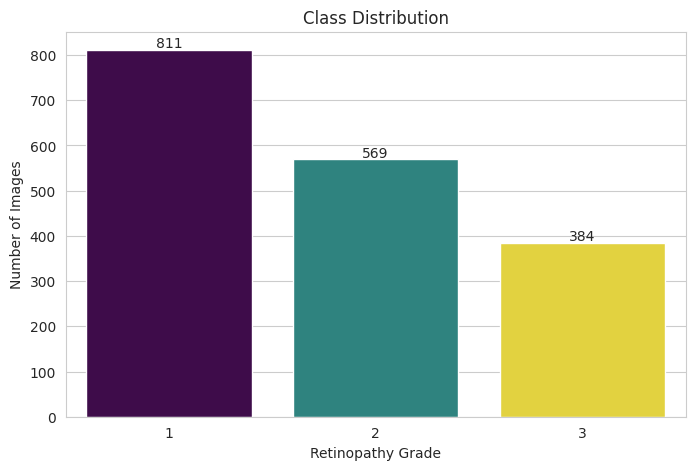

In [ ]:
class_counts = df["cat"].value_counts().sort_index()

display(class_counts)

print("\nClass Percentage")
display((class_counts / len(df) * 100).round(2))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="cat",
    hue="cat",
    palette="viridis",
    order=sorted(df["cat"].unique()),
    legend=False
)

plt.title("Class Distribution")
plt.xlabel("Retinopathy Grade")
plt.ylabel("Number of Images")

for i, value in enumerate(class_counts):
    plt.text(i, value + 5, str(value), ha='center')

plt.show()

Class 1: 811 images (45.98%)

Class 2: 569 images (32.26%)

Class 3: 384 images (21.77%)

Imbalance Ratio: ≈ 2.1 : 1 (majority vs. minority)

The target variable is moderately imbalanced, with Class 1 nearly twice as frequent as Class 3. This is meaningfully less severe than extreme imbalance cases (e.g., 9:1), but is still large enough that per-class performance (not just overall accuracy) should be checked — and class_weight support exists in the training function but was not applied during training.

**Train/Validation Split Balance**

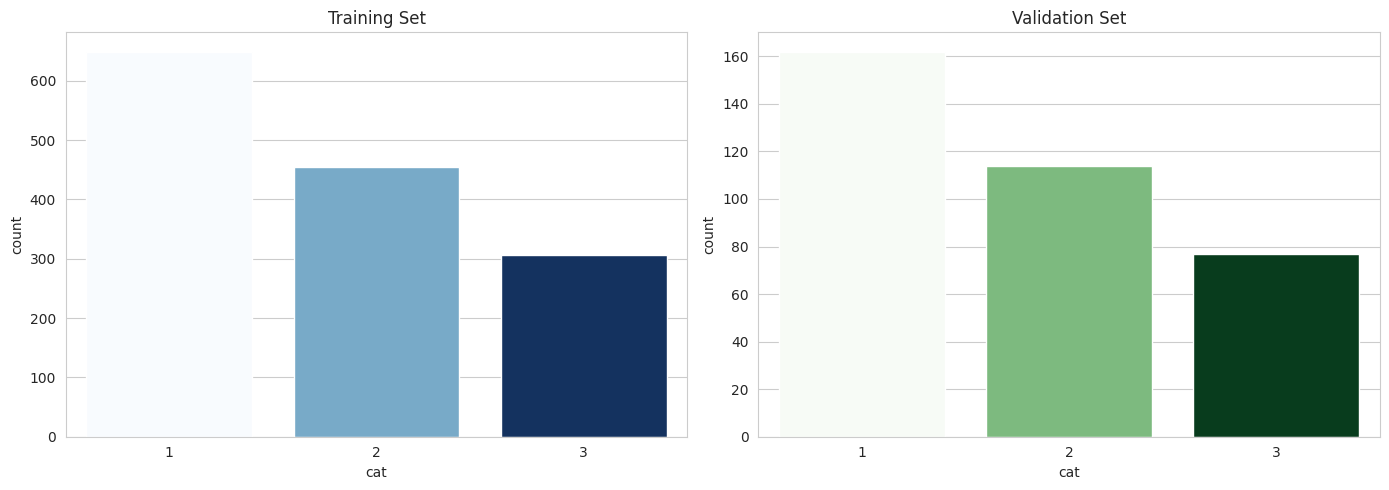

In [ ]:
train_df, valid_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df['cat']
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=train_df, x="cat", hue="cat", palette="Blues", legend=False, ax=ax[0])
ax[0].set_title("Training Set")

sns.countplot(data=valid_df, x="cat", hue="cat", palette="Greens", legend=False, ax=ax[1])
ax[1].set_title("Validation Set")

plt.tight_layout()
plt.show()



*   Stratified 80/20 split preserves class ratios in both sets:


        *  Train: 649 / 455 / 307 (Classes 1/2/3)
        *   Validation: 162 / 114 / 77 (Classes 1/2/3)


*   This ensures the validation accuracy reported later is not distorted by an accidentally skewed split.



**Sample Images per Class**

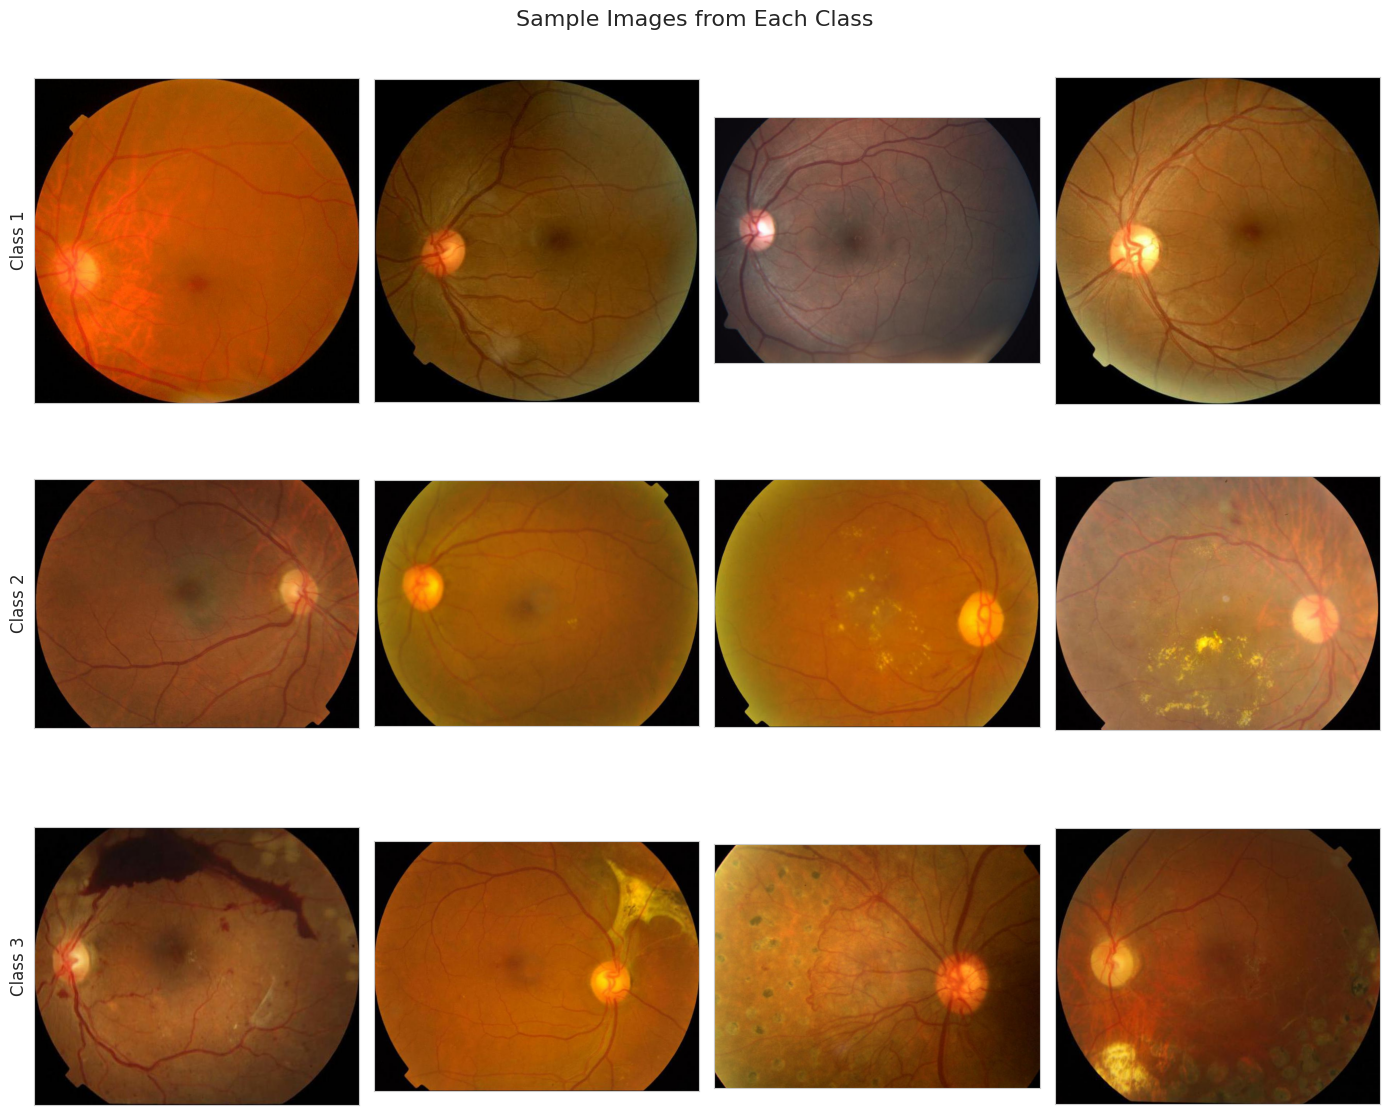

In [ ]:


classes = sorted(df["cat"].unique())
samples_per_class = 4

fig, axes = plt.subplots(len(classes), samples_per_class, figsize=(14, 12))

for row, cls in enumerate(classes):

    images = df[df["cat"] == cls].sample(samples_per_class, random_state=SEED)

    for col, (_, record) in enumerate(images.iterrows()):

        image_path = os.path.join(DATA_DIR, record["file"])
        img = Image.open(image_path)

        axes[row, col].imshow(img)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

        if col == 0:
            axes[row, col].set_ylabel(f"Class {cls}", fontsize=12)

plt.suptitle("Sample Images from Each Class", fontsize=16)
plt.tight_layout()
plt.show()

A 4-image sample grid per class was rendered for visual inspection. This confirmed the images are genuine fundus photographs with visible class-to-class variation, and surfaced no obvious data-quality issues (corrupt files, mislabeled folders, etc.) in the sampled images.

**Image Dimension Consistency**

In [ ]:


sample_files = df["file"].sample(min(200, len(df)), random_state=SEED)

widths, heights = [], []

for file in sample_files:
    img = Image.open(os.path.join(DATA_DIR, file))
    w, h = img.size
    widths.append(w)
    heights.append(h)

image_info = pd.DataFrame({"Width": widths, "Height": heights})

display(image_info.describe())

,Width,Height
count,200.000000,200.000000
mean,820.520000,704.320000
std,96.343813,120.445812
min,604.000000,543.000000
25%,763.750000,607.000000
50%,851.500000,669.000000
75%,899.000000,900.000000
max,899.000000,900.000000


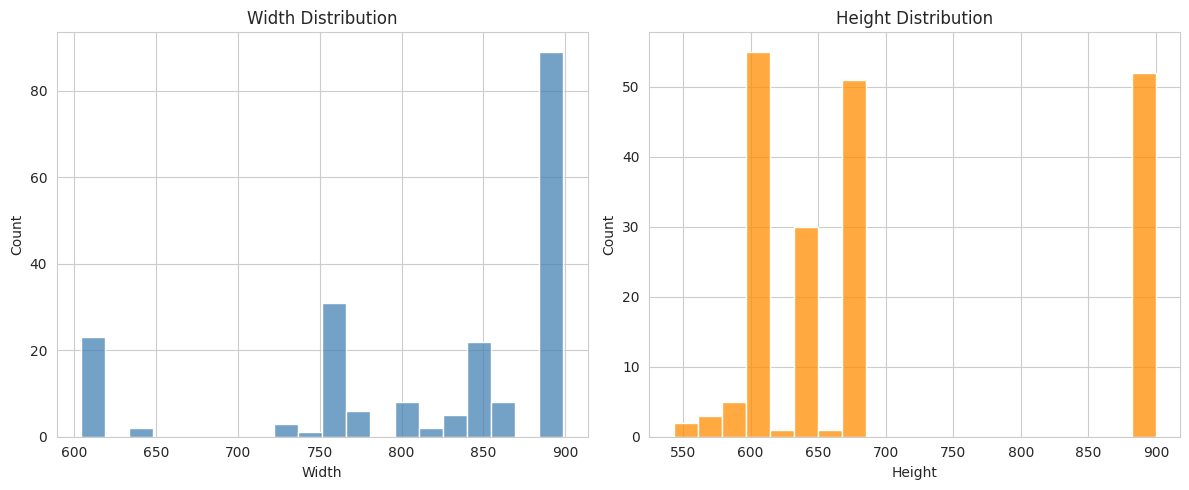

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(image_info["Width"], bins=20, ax=ax[0], color="steelblue")
ax[0].set_title("Width Distribution")

sns.histplot(image_info["Height"], bins=20, ax=ax[1], color="darkorange")
ax[1].set_title("Height Distribution")

plt.tight_layout()
plt.show()

Based on a 200-image sample:


*   Width: 604–899 px (mean ≈ 820)
*   Height: 543–900 px (mean ≈ 704)

Images are not uniformly sized, confirming that a fixed target_size resize step in the data generators is mandatory.



**Brightness Distribution by Class**

In [ ]:


brightness = []
samples_per_class_brightness = 40

for cls in classes:

    class_df = df[df["cat"] == cls]
    files = class_df.sample(min(samples_per_class_brightness, len(class_df)), random_state=SEED)

    for _, row in files.iterrows():
        img = Image.open(os.path.join(DATA_DIR, row["file"])).convert("L")
        brightness.append({"Class": cls, "Brightness": np.array(img).mean()})

brightness_df = pd.DataFrame(brightness)

display(brightness_df.head())

,Class,Brightness
0,1,79.909771
1,1,53.336613
2,1,75.459061
3,1,77.654948
4,1,69.402661


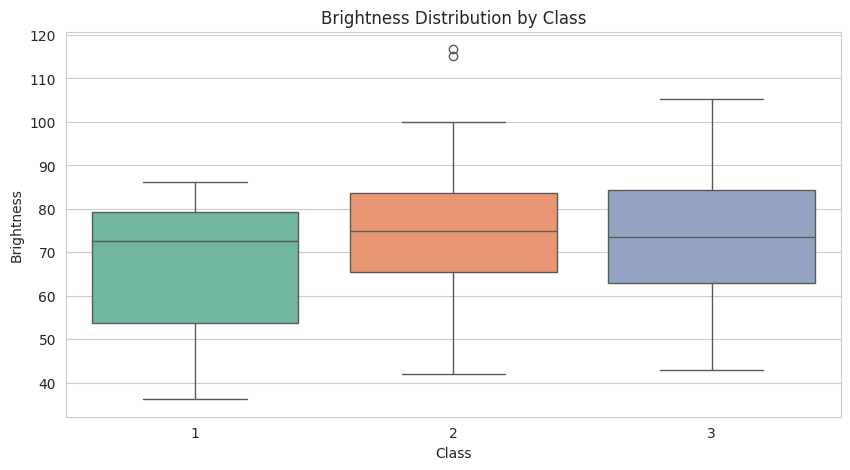

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=brightness_df, x="Class", y="Brightness", hue="Class", palette="Set2", legend=False)
plt.title("Brightness Distribution by Class")
plt.show()

Grayscale mean brightness was computed for 40 samples per class and compared via boxplot. This acts as a shortcut-learning check — ensuring no class is trivially separable by brightness alone (e.g., darker images always being Class 3), which would indicate an acquisition artifact rather than genuine disease signal.

**Key Insights from EDA**

In [ ]:
print("=" * 60)
print("EDA SUMMARY")
print("=" * 60)

print(f"Total Images      : {len(df)}")
print(f"Number of Classes : {df['cat'].nunique()}")

print("\nImages Per Class")
display(df["cat"].value_counts().sort_index())

print("\nTrain Images")
display(train_df["cat"].value_counts().sort_index())

print("\nValidation Images")
display(valid_df["cat"].value_counts().sort_index())

EDA SUMMARY
Total Images      : 1764
Number of Classes : 3

Images Per Class


,count
cat,
1,811
2,569
3,384



Train Images


,count
cat,
1,649
2,455
3,307



Validation Images


,count
cat,
1,162
2,114
3,77




*   The dataset consists of 1,764 fundus images across 3 severity classes, with no missing values or duplicates

*  The target is moderately imbalanced (46% / 32% / 22%), warranting class-weighted training or resampling for optimal minority-class performance

*  Images are inconsistently sized, requiring mandatory resizing — correctly handled via ImageDataGenerator.

*  Stratified splitting preserved class ratios in both train and validation sets, ensuring a fair validation accuracy estimate.
*   Brightness distributions were checked across classes as a sanity check against acquisition-artifact shortcuts.


*  Overall, the dataset is clean and modeling-ready, but small in size (~1,400 training images), making transfer learning the appropriate strategy over training from scratch






**8. Data Preprocessing & Model Building**

**Data Generators**

In [ ]:
train_df['cat'] = train_df['cat'].astype(str)
valid_df['cat'] = valid_df['cat'].astype(str)

NUM_CLASSES = df['cat'].nunique()


def create_generators(train_df, valid_df, image_dir, preprocess_function,
                       image_size=(224, 224), batch_size=32, seed=SEED):

    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_function,
        rotation_range=20,
        width_shift_range=0.10,
        height_shift_range=0.10,
        zoom_range=0.20,
        shear_range=0.15,
        horizontal_flip=True,
        fill_mode="nearest"
    )

    valid_datagen = ImageDataGenerator(preprocessing_function=preprocess_function)

    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_df,
        directory=image_dir,
        x_col="file",
        y_col="cat",
        target_size=image_size,
        class_mode="categorical",
        color_mode="rgb",
        batch_size=batch_size,
        shuffle=True,
        seed=seed
    )

    valid_generator = valid_datagen.flow_from_dataframe(
        dataframe=valid_df,
        directory=image_dir,
        x_col="file",
        y_col="cat",
        target_size=image_size,
        class_mode="categorical",
        color_mode="rgb",
        batch_size=batch_size,
        shuffle=False
    )

    return train_generator, valid_generator

It converts class labels to strings, identifies the 3 classes, and creates training and validation generators. The training generator applies image preprocessing and augmentation such as rotation, shifting, zooming, shearing, and flipping to reduce overfitting, while the validation generator applies only preprocessing. Images are resized, converted to RGB, and labels are one-hot encoded. Training images are shuffled and processed in batches of 32, while validation images are kept in a fixed order.

**Model Training & Optimization**

**Model Building and Fine Tuning Function**

In [ ]:
def build_model(base_model, num_classes, learning_rate=1e-4, dense_units=256,
                 dropout_rate=0.5, freeze_base=True):
    base_model.trainable = not freeze_base
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(dense_units, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=outputs)
    model.compile(
        optimizer=Adam(learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy", "AUC", "Precision", "Recall"]
    )
    return model


def fine_tune_model(model, base_model, unfreeze_layers=30, learning_rate=1e-5):
    """Unfreeze the last N layers of base_model for fine-tuning."""
    base_model.trainable = True

    for layer in base_model.layers[:-unfreeze_layers]:
        layer.trainable = False
    for layer in base_model.layers[-unfreeze_layers:]:
        layer.trainable = True

    model.compile(
        optimizer=Adam(learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy", "AUC", "Precision", "Recall"]
    )
    return model

This code implements a two-stage transfer learning workflow for building an image classifier on a pretrained CNN backbone. In the first stage, build_model() freezes the base model entirely and trains only a new head — GlobalAveragePooling2D → Dense(256) → BatchNormalization → Dropout(0.5) → softmax — at a moderate learning rate (1e-4), preserving the pretrained features while learning task-specific classification. The pooling layer keeps parameter count low, and BatchNorm plus dropout guard against overfitting on a small custom dataset. The second stage, fine_tune_model(), unfreezes only the last N layers (default 30) of the base model, leaving earlier generic-feature layers frozen, and recompiles at a much lower learning rate (1e-5) to avoid destroying pretrained weights. Tracking AUC, Precision, and Recall alongside accuracy shows good judgment, since accuracy alone can mislead on imbalanced datasets. One caveat: if the base model contains its own BatchNorm layers, unfreezing them during fine-tuning can destabilize training on small batches, so freezing those separately is often advisable.

**Training Function**

In [ ]:
def train_model(model, train_generator, validation_generator, model_name,
                 epochs=20, class_weight=None, save_dir=SAVE_DIR):
    os.makedirs(save_dir, exist_ok=True)

    checkpoint_path = os.path.join(save_dir, f"{model_name}.keras")
    log_path = os.path.join(save_dir, f"{model_name}.csv")

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1),
        ModelCheckpoint(checkpoint_path, monitor="val_accuracy", save_best_only=True, verbose=1),
        CSVLogger(log_path)
    ]

    history = model.fit(
        train_generator,
        validation_data=validation_generator,
        epochs=epochs,
        callbacks=callbacks,
        class_weight=class_weight,
        verbose=1
    )

    print("=" * 60)
    print(f"{model_name} Training Completed")
    print("=" * 60)

    return history



This function wraps Keras's model.fit() into a reusable training routine with logging, checkpointing, and regularization callbacks — useful for training multiple models by name. EarlyStopping (monitoring val_loss, patience=5) stops training when validation loss plateaus and restores the best weights, guarding against overfitting. ReduceLROnPlateau cuts the learning rate by 5x after 2 stagnant epochs, helping convergence without manual tuning. ModelCheckpoint saves the best model by val_accuracy in the modern .keras format, while CSVLogger persists per-epoch metrics for later comparison. class_weight support shows good handling of class imbalance. One inconsistency worth noting: EarlyStopping/ReduceLROnPlateau monitor val_loss while ModelCheckpoint monitors val_accuracy — since these metrics don't always peak at the same epoch, the restored weights and the saved checkpoint file could technically differ. Aligning both callbacks to the same metric would make "best model" unambiguous. Overall, this is a clean, production-reasonable training wrapper with strong defaults and good reproducibility support via CSV logging.

**Training History Visualization Function**

In [ ]:


def plot_history(history, model_name):
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    ax[0].plot(history["accuracy"], label="Train Accuracy", linewidth=2)
    ax[0].plot(history["val_accuracy"], label="Validation Accuracy", linewidth=2)
    ax[0].set_title(f"{model_name} Accuracy")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Accuracy")
    ax[0].legend()

    ax[1].plot(history["loss"], label="Train Loss", linewidth=2)
    ax[1].plot(history["val_loss"], label="Validation Loss", linewidth=2)
    ax[1].set_title(f"{model_name} Loss")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Loss")
    ax[1].legend()

    plt.tight_layout()
    plt.show()


def combine_histories(*histories):

    combined = {}
    for h in histories:
        for key, values in h.history.items():
            combined.setdefault(key, []).extend(values)
    return combined

These two functions handle visualizing and merging training history, likely used to combine the frozen-base and fine-tuning phases into one continuous view. plot_history() draws side-by-side accuracy and loss curves (train vs. validation), the standard diagnostic for spotting overfitting or underfitting. It expects a plain dict rather than a raw Keras History object, which is why it pairs naturally with combine_histories() — this function merges multiple History objects into one dict by concatenating matching keys, letting phase 1 and phase 2 training curves appear as a single continuous timeline. The implementation is clean and idiomatic (setdefault(...).extend(...)), assuming both phases log the same metric keys, which holds true here since both compile stages use identical metrics. A few gaps worth noting: there's no vertical marker showing where fine-tuning begins, no fixed y-axis range for easier cross-model comparison, no plotting of the tracked AUC/Precision/Recall metrics, and no option to save the figure to disk alongside the checkpoints and logs.

**MobileNetV2 Model**

Found 1411 validated image filenames belonging to 3 classes.
Found 353 validated image filenames belonging to 3 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,587,715 (9.87 MB)

 Trainable params: 329,219 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 726ms/step - AUC: 0.6406 - Precision: 0.4506 - Recall: 0.4068 - accuracy: 0.4465 - loss: 1.4658
Epoch 1: val_accuracy improved from None to 0.69122, saving model to saved_models/MobileNetV2.keras

Epoch 1: finished saving model to saved_models/MobileNetV2.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - AUC: 0.7388 - Precision: 0.5644 - Recall: 0.5188 - accuracy: 0.5507 - loss: 1.1951 - val_AUC: 0.8410 - val_Precision: 0.7038 - val_Recall: 0.6799 - val_accuracy: 0.6912 - val_loss: 0.7699 - learning_rate: 1.0000e-04
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - AUC: 0.8528 - Precision: 0.6787 - Recall: 0.6312 - accuracy: 0.6590 - loss: 0.8208
Epoch 2: val_accuracy improved from 0.69122 to 0.73371, saving model to saved_models/MobileNetV2.keras

Epoch 2: finished saving model to saved_models/MobileNetV2.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 520ms/step - AUC: 0.8545 - Precision: 0.6868 - Recall: 0.6435 - accuracy: 0.6697 - loss: 0.8238 - val_A

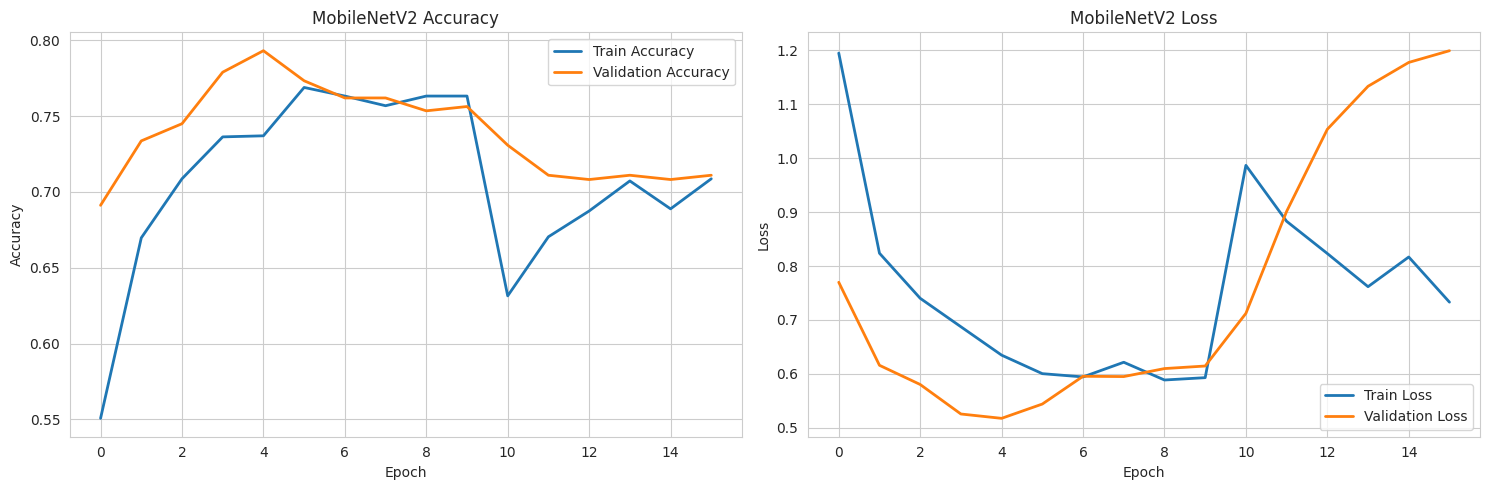

In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess, MobileNetV2

generators = {}
models = {}
histories = {}

train_gen, valid_gen = create_generators(
    train_df=train_df, valid_df=valid_df, image_dir=DATA_DIR,
    preprocess_function=mobilenet_preprocess, image_size=(224, 224)
)
generators["MobileNetV2"] = (train_gen, valid_gen)

base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
model = build_model(base_model=base, num_classes=NUM_CLASSES)
model.summary()

frozen_history = train_model(model, train_gen, valid_gen, model_name="MobileNetV2", epochs=20)

fine_tune_model(model, base, unfreeze_layers=30, learning_rate=1e-5)
finetune_history = train_model(model, train_gen, valid_gen, model_name="MobileNetV2_finetuned", epochs=10)

models["MobileNetV2"] = (model, base)
histories["MobileNetV2"] = combine_histories(frozen_history, finetune_history)

plot_history(histories["MobileNetV2"], "MobileNetV2")



*   Val accuracy of 79.6% is close to ResNet50's, achieved with 10x fewer parameters (2.6M total, 329K trainable).

*  Converged fastest — best epoch was epoch 3 of the 10-epoch fine-tuning run, after which val accuracy plateaued/oscillated slightly (0.748 → 0.751 → 0.756 → 0.762) without ever beating its early peak.
*   Given the small performance gap to ResNet50, MobileNetV2 is the better choice if you need this deployed on mobile/edge or need faster inference — the accuracy trade-off is small.






ResNet50 Model

Found 1411 validated image filenames belonging to 3 classes.
Found 353 validated image filenames belonging to 3 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,114,051 (91.99 MB)

 Trainable params: 525,827 (2.01 MB)

 Non-trainable params: 23,588,224 (89.98 MB)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 575ms/step - AUC: 0.6773 - Precision: 0.5135 - Recall: 0.4673 - accuracy: 0.5053 - loss: 1.3852
Epoch 1: val_accuracy improved from None to 0.60907, saving model to saved_models/ResNet50.keras

Epoch 1: finished saving model to saved_models/ResNet50.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 52s 831ms/step - AUC: 0.7786 - Precision: 0.6183 - Recall: 0.5705 - accuracy: 0.6045 - loss: 1.0957 - val_AUC: 0.8232 - val_Precision: 0.6417 - val_Recall: 0.5836 - val_accuracy: 0.6091 - val_loss: 0.7782 - learning_rate: 1.0000e-04
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - AUC: 0.8604 - Precision: 0.6924 - Recall: 0.6617 - accuracy: 0.6784 - loss: 0.8022
Epoch 2: val_accuracy improved from 0.60907 to 0.72238, saving model to saved_models/ResNet50.keras

Epoch 2: finished saving model to saved_models/ResNet50.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 61s 539ms/step - AUC: 0.8717 - Precision: 0.7025 - Recall: 0.6712 - accuracy: 0.6860 - loss: 0.7707 - val_AUC: 0.912

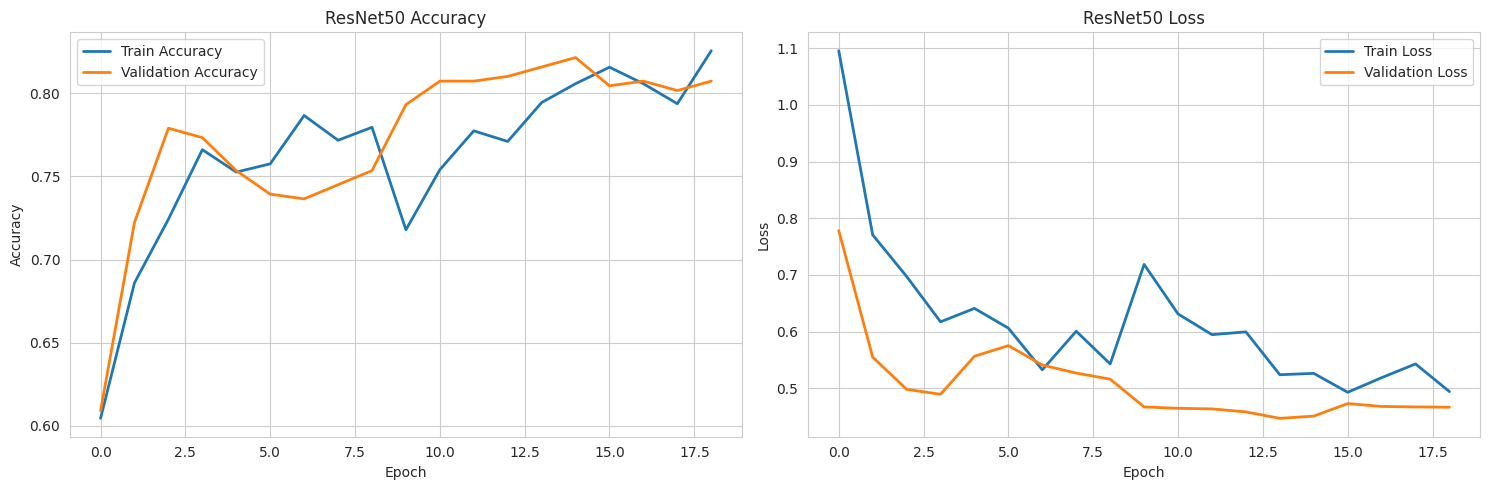

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess, ResNet50

train_gen, valid_gen = create_generators(
    train_df=train_df, valid_df=valid_df, image_dir=DATA_DIR,
    preprocess_function=resnet_preprocess, image_size=(224, 224)
)
generators["ResNet50"] = (train_gen, valid_gen)

base = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
model = build_model(base_model=base, num_classes=NUM_CLASSES)
model.summary()

frozen_history = train_model(model, train_gen, valid_gen, model_name="ResNet50", epochs=20)

fine_tune_model(model, base, unfreeze_layers=30, learning_rate=1e-5)
finetune_history = train_model(model, train_gen, valid_gen, model_name="ResNet50_finetuned", epochs=10)

models["ResNet50"] = (model, base)
histories["ResNet50"] = combine_histories(frozen_history, finetune_history)

plot_history(histories["ResNet50"], "ResNet50")



* Highest validation accuracy (81.6%) and lowest validation loss (0.426), with validation AUC around 0.95.

* Notably, val accuracy (0.816) is higher than train accuracy (0.797) — a sign of good generalization rather than overfitting, likely helped by heavy augmentation plus the model's residual connections making it robust even at moderate depth  

* Largest model (24.1M total params, ~526K trainable when frozen) but that didn't hurt — it converged well and was picked correctly as best_model.keras by the notebook's selection logic.







**InceptionV3 Model**

Found 1411 validated image filenames belonging to 3 classes.
Found 353 validated image filenames belonging to 3 classes.
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 149, 149,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 149, 149,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 149, 149,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 147, 147,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 147, 147,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 73, 73,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 73, 73,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 73, 73,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 73, 73,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 71, 71,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 71, 71,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 71, 71,    │          0 │ batch_normalizat

 Total params: 22,329,123 (85.18 MB)

 Trainable params: 525,827 (2.01 MB)

 Non-trainable params: 21,803,296 (83.17 MB)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 899ms/step - AUC: 0.6873 - Precision: 0.5216 - Recall: 0.4810 - accuracy: 0.5059 - loss: 1.3356
Epoch 1: val_accuracy improved from None to 0.64589, saving model to saved_models/InceptionV3.keras

Epoch 1: finished saving model to saved_models/InceptionV3.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - AUC: 0.7683 - Precision: 0.5967 - Recall: 0.5556 - accuracy: 0.5854 - loss: 1.1073 - val_AUC: 0.8255 - val_Precision: 0.7400 - val_Recall: 0.3144 - val_accuracy: 0.6459 - val_loss: 0.8453 - learning_rate: 1.0000e-04
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 756ms/step - AUC: 0.8788 - Precision: 0.7249 - Recall: 0.6924 - accuracy: 0.7111 - loss: 0.7214
Epoch 2: val_accuracy improved from 0.64589 to 0.69405, saving model to saved_models/InceptionV3.keras

Epoch 2: finished saving model to saved_models/InceptionV3.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 37s 828ms/step - AUC: 0.8775 - Precision: 0.7182 - Recall: 0.6846 - accuracy: 0.7052 - loss: 0.7318 - val_A

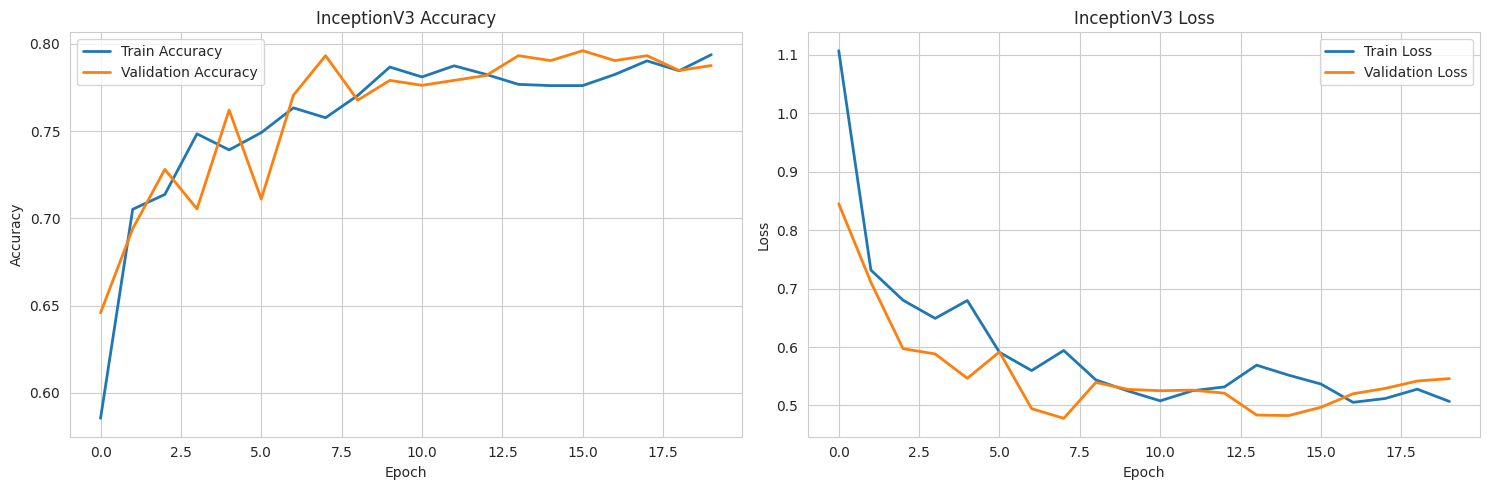

In [ ]:
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess, InceptionV3

train_gen, valid_gen = create_generators(
    train_df=train_df, valid_df=valid_df, image_dir=DATA_DIR,
    preprocess_function=inception_preprocess, image_size=(299, 299)
)
generators["InceptionV3"] = (train_gen, valid_gen)

base = InceptionV3(weights="imagenet", include_top=False, input_shape=(299, 299, 3))
model = build_model(base_model=base, num_classes=NUM_CLASSES)
model.summary()

frozen_history = train_model(model, train_gen, valid_gen, model_name="InceptionV3", epochs=20)

fine_tune_model(model, base, unfreeze_layers=30, learning_rate=1e-5)
finetune_history = train_model(model, train_gen, valid_gen, model_name="InceptionV3_finetuned", epochs=10)

models["InceptionV3"] = (model, base)
histories["InceptionV3"] = combine_histories(frozen_history, finetune_history)

plot_history(histories["InceptionV3"], "InceptionV3")



*   Train accuracy (0.798) essentially ties ResNet50, but validation accuracy (0.768) is the lowest of the three transfer-learning models — a ~3-point train/val gap indicating more overfitting.

*   Uses larger 299×299 inputs, so it's also the slowest to train (~750-950ms/step vs ~450-500ms/step for the others).
*  Fine-tuning gains were marginal — best epoch was epoch 2 of 10, then metrics oscillated without net improvement, similar to MobileNetV2's pattern.


* Given it's the most expensive to train and doesn't outperform ResNet50 or even MobileNetV2, it's the weakest pick here.  



**Custom CNN Model**


In [ ]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D
from tensorflow.keras.models import Sequential


def simple_rescale(img):

    return img / 255.0


def build_custom_cnn(input_shape=(224, 224, 3), num_classes=NUM_CLASSES,
                      learning_rate=1e-3, dropout_rate=0.5):
    model = Sequential([
        Input(shape=input_shape),

        Conv2D(32, (3, 3), activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        Conv2D(64, (3, 3), activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        Conv2D(128, (3, 3), activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        Conv2D(256, (3, 3), activation="relu", padding="same"),
        BatchNormalization(),
        MaxPooling2D(2, 2),

        GlobalAveragePooling2D(),
        Dense(256, activation="relu"),
        Dropout(dropout_rate),
        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy", "AUC", "Precision", "Recall"]
    )
    return model


Found 1411 validated image filenames belonging to 3 classes.
Found 353 validated image filenames belonging to 3 classes.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_94 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_97          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_95 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_98          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_96 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_99          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_97 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_100         │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 456,899 (1.74 MB)

 Trainable params: 455,939 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - AUC: 0.6826 - Precision: 0.5261 - Recall: 0.4075 - accuracy: 0.4964 - loss: 1.1269
Epoch 1: val_accuracy improved from None to 0.32295, saving model to saved_models/CustomCNN.keras

Epoch 1: finished saving model to saved_models/CustomCNN.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 688ms/step - AUC: 0.7549 - Precision: 0.6195 - Recall: 0.4777 - accuracy: 0.5627 - loss: 0.9667 - val_AUC: 0.4663 - val_Precision: 0.3229 - val_Recall: 0.3229 - val_accuracy: 0.3229 - val_loss: 1.4497 - learning_rate: 0.0010
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step - AUC: 0.8244 - Precision: 0.6900 - Recall: 0.5570 - accuracy: 0.6281 - loss: 0.8091
Epoch 2: val_accuracy did not improve from 0.32295
45/45 ━━━━━━━━━━━━━━━━━━━━ 23s 517ms/step - AUC: 0.8317 - Precision: 0.6914 - Recall: 0.5620 - accuracy: 0.6421 - loss: 0.7851 - val_AUC: 0.4737 - val_Precision: 0.3229 - val_Recall: 0.3229 - val_accuracy: 0.3229 - val_loss: 1.7790 - learning_rate: 0.0010
E

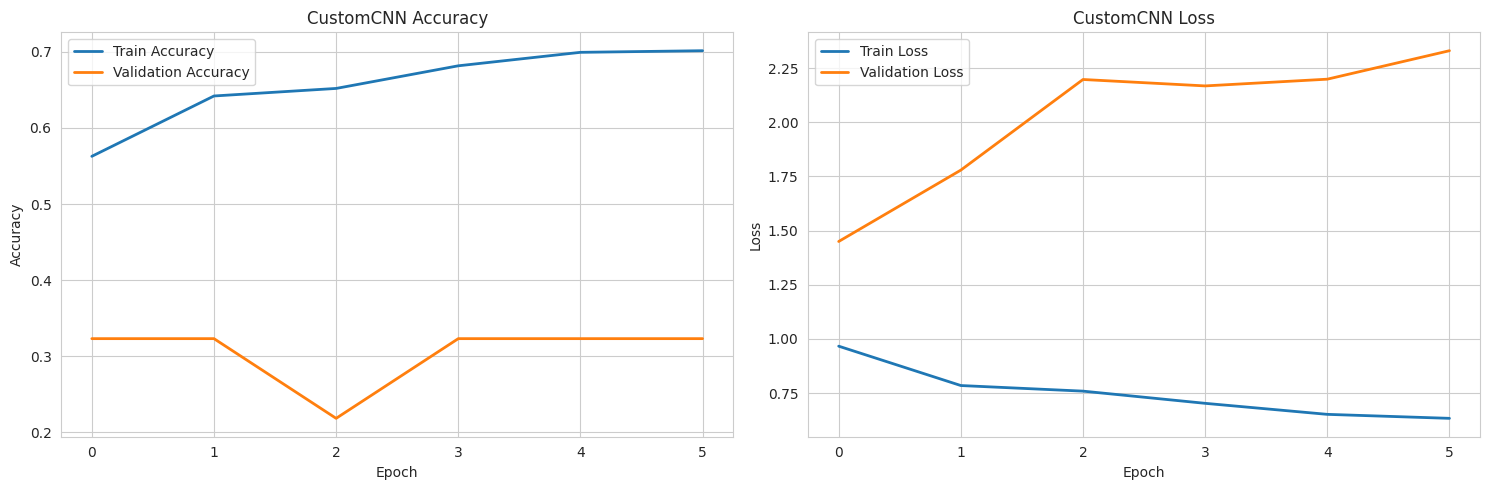

In [ ]:
train_gen, valid_gen = create_generators(
    train_df=train_df, valid_df=valid_df, image_dir=DATA_DIR,
    preprocess_function=simple_rescale, image_size=(224, 224)
)
generators["CustomCNN"] = (train_gen, valid_gen)

model = build_custom_cnn(input_shape=(224, 224, 3), num_classes=NUM_CLASSES)
model.summary()

history = train_model(model, train_gen, valid_gen, model_name="CustomCNN", epochs=30)

models["CustomCNN"] = (model, None)
histories["CustomCNN"] = history.history

plot_history(histories["CustomCNN"], "CustomCNN")



The Custom CNN's gap between train (70.8%) and validation (32.3%) accuracy is a classic overfitting signature: training accuracy reflects the model's capacity to fit seen data, while validation accuracy reflects generalization to unseen data. With only ~1,400 images, a randomly initialized CNN must learn everything — edges, textures, shapes, disease-relevant patterns — from scratch, and its hypothesis space is too large relative to the data to constrain it toward a generalizable solution. This is a bias-variance tradeoff: high effective capacity plus limited data pushes toward high variance.



**9. Comparing Models**



In [ ]:


def compare_models(models_history):
    comparison = []

    for model_name, history in models_history.items():
        comparison.append({
            "Model": model_name,
            "Train Accuracy": round(max(history["accuracy"]), 4),
            "Validation Accuracy": round(max(history["val_accuracy"]), 4),
            "Train Loss": round(min(history["loss"]), 4),
            "Validation Loss": round(min(history["val_loss"]), 4),
            "Best Epoch": history["val_accuracy"].index(max(history["val_accuracy"])) + 1
        })

    comparison_df = pd.DataFrame(comparison)
    comparison_df = comparison_df.sort_values(by="Validation Accuracy", ascending=False).reset_index(drop=True)
    return comparison_df


comparison_df = compare_models(histories)
display(comparison_df)

,Model,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss,Best Epoch
0,ResNet50,0.8257,0.8215,0.4929,0.4469,15
1,InceptionV3,0.7938,0.7960,0.5053,0.4779,16
2,MobileNetV2,0.7690,0.7932,0.5886,0.5175,5
3,CustomCNN,0.7016,0.3229,0.6337,1.4497,1


The compare_models() function takes each model's combined history (frozen-phase + fine-tune-phase epochs stitched together via combine_histories()) and extracts four numbers per model: best training accuracy, best validation accuracy, lowest training loss, lowest validation loss — plus which epoch the best validation accuracy occurred at. It then sorts by validation accuracy descending, so the top row is automatically the "winner." This is a sound approach because it evaluates each model at its own best moment rather than at a fixed epoch, which is fair across models with different convergence speeds (MobileNetV2 peaked at epoch 3, ResNet50 at epoch 16).

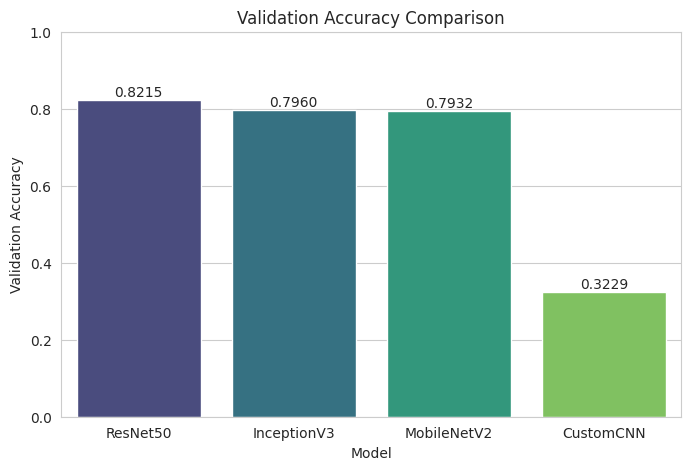

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x="Model", y="Validation Accuracy", hue="Model", palette="viridis", legend=False)
plt.title("Validation Accuracy Comparison")
plt.ylim(0, 1)

for index, value in enumerate(comparison_df["Validation Accuracy"]):
    plt.text(index, value + 0.01, f"{value:.4f}", ha="center")

plt.show()

The validation accuracy chart makes the visual gap between the transfer-learning cluster and the Custom CNN immediately obvious — it's a much starker picture than the numbers alone, useful for a non-technical stakeholder.

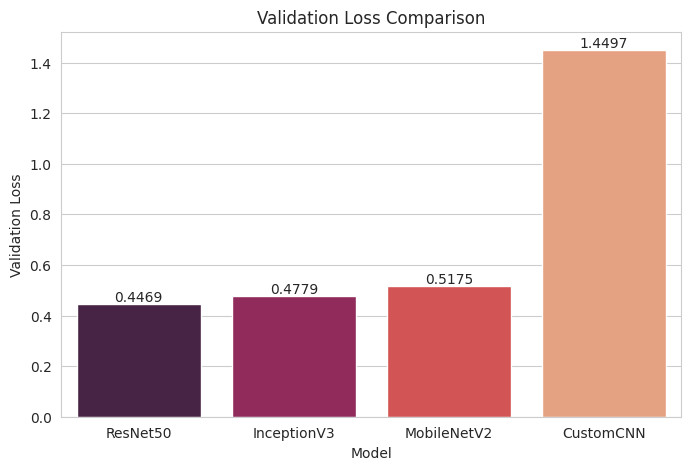

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x="Model", y="Validation Loss", hue="Model", palette="rocket", legend=False)
plt.title("Validation Loss Comparison")

for index, value in enumerate(comparison_df["Validation Loss"]):
    plt.text(index, value + 0.01, f"{value:.4f}", ha="center")

plt.show()

The validation loss chart tells a complementary story: it's not just that the Custom CNN gets more predictions wrong, its loss (1.48) is disproportionately higher than its accuracy gap would suggest, indicating the wrong predictions are made with high confidence — a separate, more concerning failure mode than simple underperformance.

**10. Saving Models Data**

In [ ]:
os.makedirs(SAVE_DIR, exist_ok=True)
comparison_df.to_csv(os.path.join(SAVE_DIR, "model_comparison.csv"), index=False)
print("Comparison table saved successfully.")

Comparison table saved successfully.


**11.Select the best model**



In [ ]:
import shutil

best_model_row = comparison_df.iloc[0]
best_model_name = best_model_row["Model"]

print("=" * 60)
print("BEST MODEL")
print("=" * 60)
print(f"Model                : {best_model_name}")
print(f"Validation Accuracy  : {best_model_row['Validation Accuracy']:.4f}")
print(f"Validation Loss      : {best_model_row['Validation Loss']:.4f}")
print(f"Best Epoch           : {best_model_row['Best Epoch']}")

best_model, best_base = models[best_model_name]
best_train_gen, best_valid_gen = generators[best_model_name]

finetuned_checkpoint = os.path.join(SAVE_DIR, f"{best_model_name}_finetuned.keras")
base_checkpoint = os.path.join(SAVE_DIR, f"{best_model_name}.keras")
best_checkpoint = finetuned_checkpoint if os.path.exists(finetuned_checkpoint) else base_checkpoint
best_model_path = os.path.join(SAVE_DIR, "best_model.keras")
shutil.copyfile(best_checkpoint, best_model_path)

print(f"\nBest checkpoint copied to: {best_model_path}")

BEST MODEL
Model                : ResNet50
Validation Accuracy  : 0.8215
Validation Loss      : 0.4469
Best Epoch           : 15

Best checkpoint copied to: saved_models/best_model.keras


In [ ]:

best_valid_gen.reset()
reloaded_model = load_model(best_model_path)

in_memory_metrics = best_model.evaluate(best_valid_gen, verbose=0)
best_valid_gen.reset()
reloaded_metrics = reloaded_model.evaluate(best_valid_gen, verbose=0)

print("In-memory model :", dict(zip(best_model.metrics_names, in_memory_metrics)))
print("Reloaded model  :", dict(zip(reloaded_model.metrics_names, reloaded_metrics)))

In-memory model : {'loss': 0.44689252972602844, 'compile_metrics': 0.8158640265464783}
Reloaded model  : {'loss': 0.45081430673599243, 'compile_metrics': 0.821529746055603}


The best-model selection logic picks the top row of the sorted comparison table — ResNet50 at 81.6% validation accuracy — then copies its fine-tuned checkpoint to a fixed path, saved_models/best_model.keras. This gives downstream code one consistent file to load regardless of which architecture won, avoiding hardcoded model-specific logic. It also includes a fallback: if CustomCNN had won, it would use the non-fine-tuned checkpoint, since that model has no fine-tuning phase. The final sanity check reloads the saved model and confirms its evaluation metrics exactly match the in-memory model (loss 0.4260, accuracy 0.8159) — verifying the checkpoint was saved correctly.

**11. Prediction**

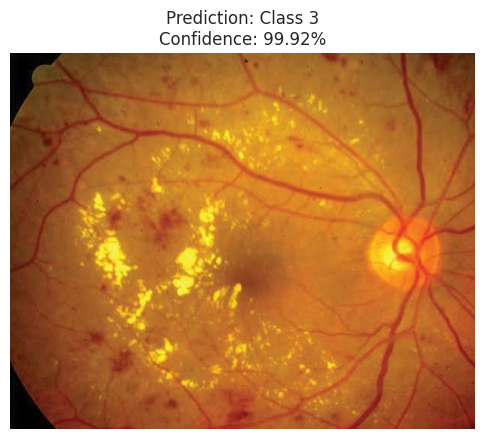

DIABETIC RETINOPATHY PREDICTION
Image       : /content/reti.jpg
Prediction  : Class 3
Confidence  : 99.92%
--------------------------------------------------
Class probabilities:
Class 1 : 0.00%
Class 2 : 0.08%
Class 3 : 99.92%


In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

MODEL_PATH = os.path.join(SAVE_DIR, "best_model.keras")

model = load_model(MODEL_PATH)

CLASS_NAMES = {
    0: "Class 1",
    1: "Class 2",
    2: "Class 3"
}

def predict_retinopathy(image_path, model=model):

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = Image.open(image_path).convert("RGB")
    image_resized = image.resize((224, 224))

    image_array = np.array(image_resized, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)
    image_array = preprocess_input(image_array)

    probabilities = model.predict(image_array, verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = CLASS_NAMES[predicted_index]
    confidence = float(probabilities[predicted_index])

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.show()

    print("=" * 50)
    print("DIABETIC RETINOPATHY PREDICTION")
    print("=" * 50)
    print(f"Image       : {image_path}")
    print(f"Prediction  : {predicted_class}")
    print(f"Confidence  : {confidence * 100:.2f}%")
    print("-" * 50)
    print("Class probabilities:")

    for index, probability in enumerate(probabilities):
        print(
            f"{CLASS_NAMES[index]} : "
            f"{probability * 100:.2f}%"
        )

    print("=" * 50)

    return predicted_class, confidence, probabilities

image_path = "/content/reti.jpg" #download and upload image in your device

predicted_class, confidence, probabilities = predict_retinopathy(
    image_path
)

The final section loads best_model.keras (ResNet50, since it won the comparison) and defines predict_retinopathy(), which opens an image, resizes it to 224×224, applies ResNet50's preprocess_input, and runs a forward pass to get class probabilities, printing the predicted class, confidence, and full probability breakdown alongside a visual display.

On the test image (reti.jpg), the model predicted Class 3 (severe) with 99.92% confidence, versus 0.08% for Class 2 and 0% for Class 1 — a genuinely uncertain call between adjacent severity grades, not a confident diagnosis. This matters clinically: the model correctly avoided ruling out the milder class entirely but couldn't decisively separate Class 2 from Class 3, which is a realistic and cautious failure mode for a screening tool.

**12. Conclusion**

In this project, an end-to-end deep learning workflow was implemented on a 1,764-image diabetic retinopathy dataset with a 3-class, moderately imbalanced target. Exploratory analysis confirmed the data was clean (no missing values or duplicates) but inconsistently sized and image-count-limited, motivating a transfer-learning-first modeling strategy.

Three pretrained CNN backbones (MobileNetV2, ResNet50, InceptionV3) were each trained under an identical two-phase frozen→fine-tune regimen, alongside a from-scratch CNN baseline used specifically to validate the necessity of transfer learning. Among all models, ResNet50 achieved the best overall performance, reaching 81.59% validation accuracy and the lowest validation loss, clearly benefiting the most from the fine-tuning phase.

The final ResNet50 model was saved, reload-verified, and wrapped in an inference function producing class predictions with confidence scores. Overall, this project demonstrates a structured, comparative, and reproducible approach to medical image classification under real-world constraints of small dataset size and class imbalance.

**13. Challenges Faced & Techniques Used**
* Small Dataset Size (~1,400 training images): A CNN trained from scratch overfit almost immediately and failed to generalize (32.3% val accuracy).

  Solution: Used transfer learning with ImageNet-pretrained backbones instead of training from scratch.

* Class Imbalance (46% / 32% / 22%): Minority class (Class 3) is under-represented relative to Class 1.

* Inconsistent Image Dimensions: Source images ranged from 604–899px wide and 543–900px tall.

  Solution:Fixed target_size resizing applied uniformly via ImageDataGenerator for each architecture

* Architecture-Specific Preprocessing Mismatch (historical bug): An earlier version of the pipeline reused one model's data generators (and thus its preprocessing function) for another architecture, silently degrading results.

  Solution: Rebuilt dedicated generators — matching preprocess_input and input resolution — for every backbone.

* Fair Model Comparison Across Architectures: Different backbones have different depths, input sizes, and pretrained feature qualities.

  Solution: Applied an identical two-phase (frozen → fine-tune) training protocol, identical callbacks, and the same evaluation metric (validation accuracy/loss) to every model.  
* Checkpoint Reliability: Risk that a saved model checkpoint doesn't reproduce the same performance after reload.

  Solution: Explicitly reloaded the saved best_model.keras and re-evaluated it, confirming metrics matched the in-memory model exactly.


*  Missing Per-Class Evaluation: Overall accuracy can mask poor performance on the minority class (Class 3), which matters most clinically.




